# Transitory A shock with price-aware re-timing

A **transitory** productivity shock: a one-period decline that lands at a fixed calendar
date `S`. A firm is hit only if it delivers at `S`; re-timing to any other date avoids it
entirely. This is the dodgeable case — the shock is an event in calendar time, not something
glued to the firm.

Calibration (`c`, `N`, `tau`) and the staggering placement are unchanged from
`semi_endo_A.ipynb`.

## The firm's problem

With CES demand and the markup rule, profit is $\pi_i \propto MC_i^{1-\sigma} P^{\sigma} C$.
Marginal cost is inversely proportional to productivity and this model closes demand with
$C = P^{\,\text{power}}$, so a firm choosing lag $t$ (delivering at $t+1$) has payoff

$$V_i(t) \;=\; \big[A(t)\,\text{tprod}_i(t)\big]^{\sigma-1}\, P_{t+1}^{\;\sigma+\text{power}},
\qquad A(t) = \begin{cases}\text{shock} & t+1 = S\\ 1 & \text{otherwise.}\end{cases}$$

Two forces act on the lag choice, and they pull in opposite directions:

- **dodging** — leave date `S` to escape the shock;
- **price-chasing** — $\sigma + \text{power} > 0$, so delivering when the price index is
  high is profitable, which draws firms *toward* crowded dates.

The lag distribution determines the price path and the price path determines the lag
distribution, so the model is solved as a fixed point.

## The result

The response is **non-monotone in shock size and vanishes above a threshold**. Dodging
costs a firm the productivity it gives up by leaving its unconstrained optimum. Once the
shock exceeds that cost for every firm, date `S` empties completely and a transitory shock
has *no aggregate effect at all* — however large it is.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

/Users/samuelzhao/anaconda3/lib/python3.10/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [2]:
sigma = 5
gamma = 1
eta   = 2
power = (1 + eta) / (-gamma - eta)

beta  = 1 / (1.0 + 0.01)
beta1 = 1 / (1.0 + 0.01 * np.exp(30 / (36.5 * 0.9)))

SHOCK_DATE = 3     # calendar date the shock lands on
TMAX       = 20    # longest lag a firm may choose
EXP        = sigma + power

## Calibration

In [3]:
data     = pd.read_csv('APP_data_usa_goods.csv', index_col=0)
data_tau = data['invtCogsRatio'] * 36.5 / (30 * 0.1)

c_grid   = np.linspace(0, 0.99, 1000)
tau_diff = np.zeros(len(c_grid))
for i, c_try in enumerate(c_grid[1:], start=1):
    N_try = -(data_tau) - 1 / np.log(beta * c_try)
    t1 = np.clip(-1 / np.log(beta  * c_try) - N_try, 0, None)
    t2 = np.clip(-1 / np.log(beta1 * c_try) - N_try, 0, None)
    tau_diff[i] = np.mean(np.abs(t1 - t2))
c = np.min(c_grid[np.abs(tau_diff - 1) == np.min(np.abs(tau_diff - 1))])

N   = np.asarray(-data_tau - 1 / np.log(beta * c))
tau = np.clip(-1 / np.log(beta * c) - N, 0, None)
tf, tc = np.floor(tau), np.ceil(tau)
pc = (beta * c) ** tc * (tc + N)
pf = (beta * c) ** tf * (tf + N)
tau = np.clip(np.where(pc > pf, tc, np.where(pc < pf, tf, tau)), 0, None).astype(int)

tau_static = tau[::-1].copy()
N_v        = N[::-1].copy()
n_firms    = len(tau_static)
print(f'calibrated c = {c:.6f};  {n_firms} firms')
print(f'{int((tau_static + 1 == SHOCK_DATE).sum())} firms deliver at S = {SHOCK_DATE} before any re-timing')

calibrated c = 0.901802;  269 firms
97 firms deliver at S = 3 before any re-timing


In [4]:
T        = np.arange(0, TMAX + 1)
FEASIBLE = (T[None, :] + N_v[:, None]) > 0      # productivity must be positive
TPROD    = np.where(FEASIBLE, (beta * c) ** T[None, :] * (T[None, :] + N_v[:, None]), np.nan)

assert np.array_equal(T[np.nanargmax(TPROD, axis=1)], tau_static), \
    'static grid argmax disagrees with the floor/ceil rounding'
print('static grid argmax reproduces the floor/ceil tau')

static grid argmax reproduces the floor/ceil tau


## Model

`shock_mask` assumes `tau` arrives sorted descending, which it does here (`tau*` reduces to
`data_tau`, and the CSV is pre-sorted). The assertion guards that, since a re-optimized
distribution that lost the ordering would silently misplace shocked cells.

In [5]:
def shock_mask(t):
    '''Boolean (period x firm) mask of delivery cells; placement as in semi_endo_A.ipynb.'''
    t = np.asarray(t)
    n = len(t) + int(t.min())
    m = int(t.max()) + int(t.min())
    missing_count = len(set(range(int(t.max()) + 1)) - set(t.tolist()))
    M = np.zeros((m + 2, n + missing_count), dtype=bool)
    count = 0
    for i in range(1, m + 2):
        k = int((t == i - 1).sum())
        for j in range(k):
            M[i, n - i - j - count] = True
        if k > 1:
            count += k - 1
    M = np.vstack([M, np.zeros(n + missing_count, dtype=bool)])
    return M[:, 0:n - int(t.min())]


def price_path(tv, shock, S=SHOCK_DATE):
    '''CES price index path; only deliveries landing on date S are shocked.'''
    assert np.all(np.diff(tv) <= 0), 'shock_mask requires tau sorted descending'
    tp = (beta * c) ** tv * (tv + N_v)
    M  = shock_mask(tv)
    A  = np.ones(M.shape)
    if S < M.shape[0]:
        A[S, :] = np.where(M[S, :], shock, 1.0)
    return (np.sum(1 / (A * tp) ** (1 - sigma), axis=1)) ** (1 / (1 - sigma))


def best_response(P, shock, S=SHOCK_DATE):
    '''Optimal lag for each firm given a price path; delivering at S incurs the shock.'''
    Pn = P / P[0]
    D  = np.ones(max(len(Pn), TMAX + 2))
    D[:len(Pn)] = Pn ** EXP
    D[len(Pn):] = Pn[-1] ** EXP
    A = np.where(T + 1 == S, shock, 1.0)[None, :]
    V = np.where(FEASIBLE, (A * TPROD) ** (sigma - 1) * D[T + 1][None, :], -np.inf)
    return T[V.argmax(axis=1)]


assert np.array_equal(best_response(np.ones(10), 1.0), tau_static), \
    'no shock and a flat price path should return the static distribution'
print('no-shock, flat-price case reproduces the static solution')

no-shock, flat-price case reproduces the static solution


In [6]:
def fixed_point(shock, S=SHOCK_DATE, max_iter=200):
    '''Iterate lag distribution <-> price path. Returns (tau, iters); iters=-2 if cycling.'''
    tv, seen = tau_static.copy(), []
    for it in range(max_iter):
        new = best_response(price_path(tv, shock, S), shock, S)
        if np.array_equal(new, tv):
            return tv, it
        key = tuple(new.tolist())
        if key in seen:
            return tv, -2
        seen.append(key)
        tv = new
    return tv, -1


def irf(tv, shock, S=SHOCK_DATE, L=16):
    P = price_path(tv, shock, S)
    C = P ** power / P[0] ** power - 1
    pad = np.zeros(len(C) + 1); pad[1:] = C
    pi = -(pad[1:] - pad[:-1])
    a = np.zeros(L); a[:min(L, len(C))]  = C[:L]
    b = np.zeros(L); b[:min(L, len(pi))] = pi[:L]
    return a, b

## The dodging threshold

A firm leaves date `S` when the shock exceeds what it loses by moving off its optimum. That
cost is the drop from the best lag to the best *other* lag, and it is small: a fraction of a
percent. The largest such cost across firms is the shock size above which **every** firm
dodges and the aggregate effect is exactly zero.

In [7]:
best   = np.nanmax(TPROD, axis=1)
second = TPROD.copy()
second[np.arange(n_firms), tau_static] = np.nan
loss = 1 - np.nanmax(second, axis=1) / best          # cost of moving one step

at_S = (tau_static + 1 == SHOCK_DATE)
print(f'cost of re-timing, all firms   : min {loss.min():.5f}  median {np.median(loss):.5f}  max {loss.max():.5f}')
print(f'cost of re-timing, firms at S  : min {loss[at_S].min():.5f}  max {loss[at_S].max():.5f}')
print(f'\npredicted threshold (max cost among firms at S): {100*loss[at_S].max():.3f}%')

cost of re-timing, all firms   : min 0.00001  median 0.00317  max 0.00637
cost of re-timing, firms at S  : min 0.00008  max 0.00634

predicted threshold (max cost among firms at S): 0.634%


## Response across shock sizes

In [8]:
pcts = [0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.65, 0.8, 1.0, 3.0, 12.0, 50.0]
rows = []
for pct in pcts:
    s = 1 - pct / 100
    f, it = fixed_point(s)
    C_, pi_ = irf(f, s)
    C_fix, _ = irf(tau_static, s)          # counterfactual: nobody re-times
    rows.append((pct, C_.min(), C_fix.min(), int((f + 1 == SHOCK_DATE).sum()), it))

print(f'{"shock":>8} {"C trough":>10} {"if no re-timing":>16} {"firms at S":>12} {"iters":>6}')
for pct, ct, cf, k, it in rows:
    tag = 'cycle' if it == -2 else ('max' if it == -1 else str(it))
    print(f'{pct:>7.2f}% {ct:>10.5f} {cf:>16.5f} {k:>8d}/{n_firms} {tag:>6}')

   shock   C trough  if no re-timing   firms at S  iters
   0.05%   -0.00021         -0.00022       92/269      1
   0.10%   -0.00041         -0.00045       89/269      1
   0.20%   -0.00074         -0.00089       80/269      2
   0.30%   -0.00098         -0.00134       70/269      2
   0.40%   -0.00089         -0.00178       47/269      3
   0.50%   -0.00064         -0.00223       27/269      3
   0.60%   -0.00031         -0.00267       11/269      5
   0.65%    0.00000         -0.00289        0/269      5
   0.80%    0.00000         -0.00355        0/269      2
   1.00%    0.00000         -0.00443        0/269      2
   3.00%    0.00000         -0.01307        0/269      1
  12.00%    0.00000         -0.04809        0/269      1
  50.00%    0.00000         -0.12695        0/269      1


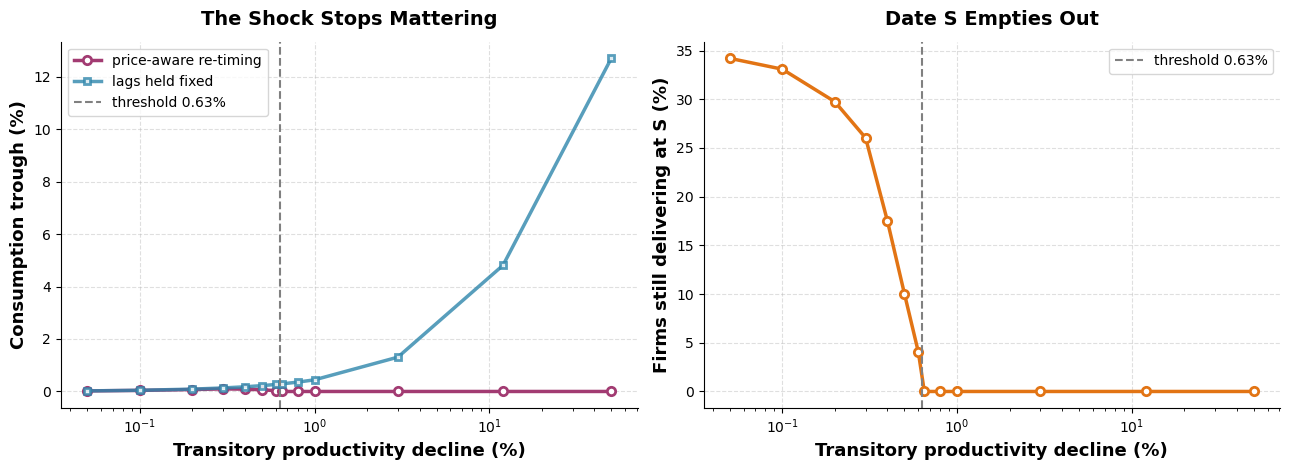

In [9]:
pct_a  = np.array([r[0] for r in rows])
trough = np.array([r[1] for r in rows])
fixed  = np.array([r[2] for r in rows])
atS    = np.array([r[3] for r in rows])
thresh = 100 * loss[at_S].max()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))

ax1.plot(pct_a, -100 * trough, lw=2.5, marker='o', markersize=6, color='#A23B72',
         markerfacecolor='white', markeredgewidth=2, label='price-aware re-timing')
ax1.plot(pct_a, -100 * fixed, lw=2.5, marker='s', markersize=5, color='#2E86AB',
         markerfacecolor='white', markeredgewidth=2, alpha=0.8, label='lags held fixed')
ax1.axvline(thresh, color='gray', linestyle='--', lw=1.5,
            label=f'threshold {thresh:.2f}%')
ax1.set_ylabel('Consumption trough (%)', fontsize=13, weight='bold')
ax1.set_title('The Shock Stops Mattering', fontsize=14, weight='bold', pad=12)

ax2.plot(pct_a, 100 * atS / n_firms, lw=2.5, marker='o', markersize=6, color='#E27414',
         markerfacecolor='white', markeredgewidth=2)
ax2.axvline(thresh, color='gray', linestyle='--', lw=1.5, label=f'threshold {thresh:.2f}%')
ax2.set_ylabel(f'Firms still delivering at S (%)', fontsize=13, weight='bold')
ax2.set_title('Date S Empties Out', fontsize=14, weight='bold', pad=12)

for ax in (ax1, ax2):
    ax.set_xscale('log')
    ax.set_xlabel('Transitory productivity decline (%)', fontsize=13, weight='bold')
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.legend(fontsize=10)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('../semi_endo_A_transitory_sizes.png', dpi=150)
plt.show()

## Impulse responses

Below the threshold the shock bites and re-timing only partly offsets it. Above it, the
paths are flat lines at zero.

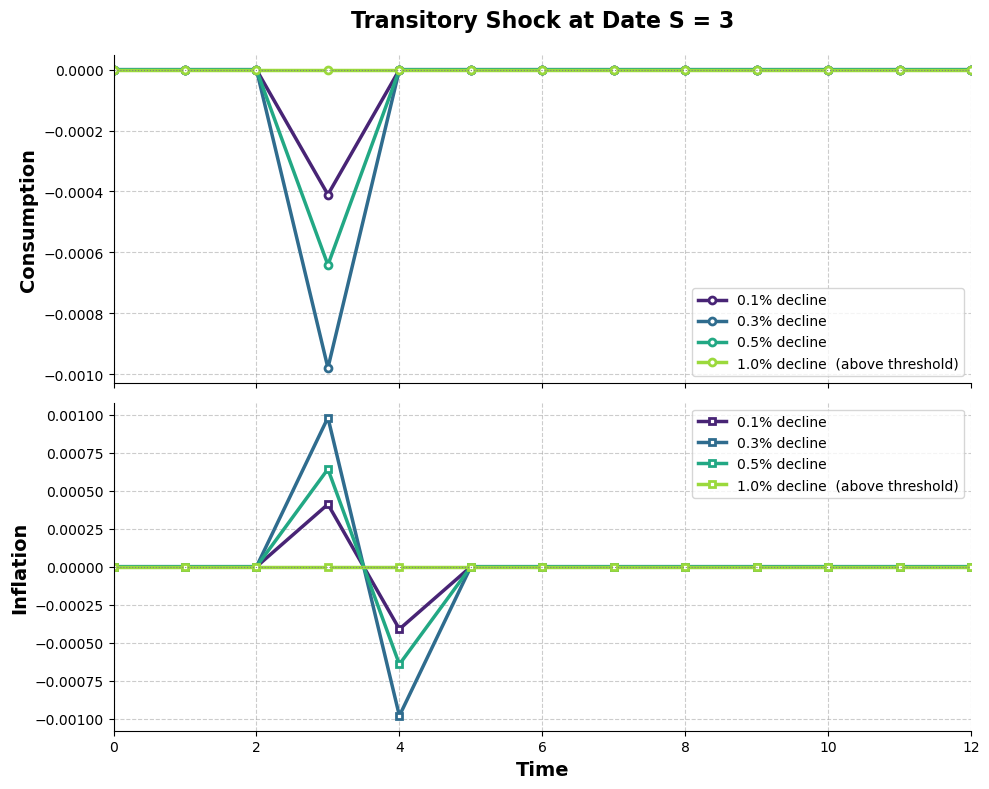

In [10]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
show = [0.1, 0.3, 0.5, 1.0]
colors = plt.cm.viridis(np.linspace(0.1, 0.85, len(show)))

for pct, col in zip(show, colors):
    s = 1 - pct / 100
    f, _ = fixed_point(s)
    C_, pi_ = irf(f, s)
    lab = f'{pct}% decline' + ('  (above threshold)' if pct > thresh / 100 * 100 else '')
    ax1.plot(C_,  lw=2.5, marker='o', markersize=5, color=col,
             markerfacecolor='white', markeredgewidth=2, label=lab)
    ax2.plot(pi_, lw=2.5, marker='s', markersize=5, color=col,
             markerfacecolor='white', markeredgewidth=2, label=lab)

ax1.set_title(f'Transitory Shock at Date S = {SHOCK_DATE}', fontsize=16, weight='bold', pad=20)
ax1.set_ylabel('Consumption', fontsize=14, weight='bold')
ax2.set_ylabel('Inflation', fontsize=14, weight='bold')
ax2.set_xlabel('Time', fontsize=14, weight='bold')
for ax in (ax1, ax2):
    ax.set_xlim(0, 12)
    ax.grid(True, linestyle='--', alpha=0.4, color='gray')
    ax.axhline(0, color='gray', linestyle=':', linewidth=0.8)
    ax.legend(fontsize=10)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('../semi_endo_A_transitory.png', dpi=150)
plt.show()

## Does the shock date matter?

`S` is a free parameter now. Dates holding more firms have more to lose, but the threshold
is set by the re-timing cost of the firms sitting there, not by how many there are.

In [11]:
print(f'{"S":>3} {"firms at S":>12} {"C trough @0.3%":>15} {"C trough @3%":>13} {"threshold":>11}')
for S in range(1, 8):
    k = int((tau_static + 1 == S).sum())
    if k == 0:
        print(f'{S:>3} {k:>8d}/{n_firms} {"-":>15} {"-":>13} {"-":>11}')
        continue
    m = (tau_static + 1 == S)
    thr = 100 * loss[m].max()
    a, _ = irf(fixed_point(0.997, S)[0], 0.997, S)
    b, _ = irf(fixed_point(0.97,  S)[0], 0.97,  S)
    print(f'{S:>3} {k:>8d}/{n_firms} {a.min():>15.5f} {b.min():>13.5f} {thr:>10.3f}%')

  S   firms at S  C trough @0.3%  C trough @3%   threshold
  1        1/269         0.00000       0.00000      0.067%
  2       31/269        -0.00034       0.00000      0.637%
  3       97/269        -0.00098       0.00000      0.634%
  4       66/269        -0.00037       0.00000      0.630%
  5       48/269        -0.00018       0.00000      0.620%
  6       18/269        -0.00003       0.00000      0.572%
  7        1/269        -0.00000       0.00000      0.603%


## Summary

- A transitory shock is **dodgeable**, and dodging is cheap: leaving the optimal lag costs
  most firms well under 1% of productivity.
- The aggregate response is therefore **non-monotone in shock size**. It peaks at a few
  tenths of a percent and then falls to exactly zero — a larger transitory shock does *less*
  damage, because it induces more firms to step out of its way.
- The threshold is not a free parameter: it is the largest one-step re-timing cost among the
  firms sitting on date `S`. Above it, date `S` empties completely and the shock has no
  aggregate effect at any magnitude.
- Compared against a counterfactual in which lags are held fixed — where the trough grows
  linearly in the shock without bound — essentially the entire difference is re-timing.

The practical implication is that a frictionless transitory shock cannot generate a
meaningful downturn in this model: any shock big enough to matter is also big enough to
dodge. Getting a non-trivial response back requires something that makes re-timing costly or
impossible for part of the distribution — a re-timing cost, or a `delta` share of firms that
cannot move.